In [83]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# To fix the ParserError, use the raw GitHub URL instead of the HTML page preview link
url = "https://raw.githubusercontent.com/bselna-lab/Selna-Data-Science-Portfolio/main/TidyData-Project/mutant_moneyball.csv"
df_wide = pd.read_csv(url)

df_wide.isna().sum()

print("Original (Untidy) Mutant Moneyball DataFrame:")
print(df_wide.head())

Original (Untidy) Mutant Moneyball DataFrame:
              Member  TotalValue60s_heritage  TotalValue70s_heritage  \
0  warrenWorthington                929056.0                154585.0   
1          hankMcCoy                929776.0                 20705.0   
2       scottSummers                933616.0                188635.0   
3         bobbyDrake                929776.0                154585.0   
4           jeanGrey                933616.0                179899.0   

   TotalValue80s_heritage  TotalValue90s_heritage  TotalValue60s_ebay  \
0                 23957.0                   960.0             23335.0   
1                  6631.0                   881.0             23377.0   
2                 29240.0                   739.0             23420.0   
3                  1514.0                   874.0             23377.0   
4                 16868.0                  1708.0             23420.0   

   TotalValue70s_ebay  TotalValue80s_ebay  TotalValue90s_ebay  \
0              33

#First: Look and Inspect the raw data

The very first thing I did was import PANDAS in order to continue with the rest of the project. The second thing I did was import the CSV file that contains the data, so I could go on to tidy the data and explore the data. I did this using the mutant_moneyball.csv. isna() .sum()` counts the missing values in each column, and `head()` shows the first rows. The data is in wide format: each of the 26 rows is an X-Men member, and the 16 value columns (like `TotalValue60s_heritage`) each combine a decade and a valuation source in the column name. This long form violates the tidy data rule that each variable should have its own column. Additionally, this shows us that we have many many missing values, especially for older decades. This is most likely due to the fact that members don't have comics from that period.



In [84]:
#Melt wide to Long
df_long = pd.melt(df_wide, id_vars=['Member'],
                  var_name='measure', value_name='value')

print("\nMelted Mutant Moneyball DataFrame:")
print(df_long.head())



Melted Mutant Moneyball DataFrame:
              Member                 measure     value
0  warrenWorthington  TotalValue60s_heritage  929056.0
1          hankMcCoy  TotalValue60s_heritage  929776.0
2       scottSummers  TotalValue60s_heritage  933616.0
3         bobbyDrake  TotalValue60s_heritage  929776.0
4           jeanGrey  TotalValue60s_heritage  933616.0


#Melting the data: Wide to Long
Because the raw data spreads one measurement across 16 separate columns, and violates our tidy data rules, I used `pd.melt()` to reshape it. 'Member' stays as the identifier column using '`id_vars`', and all 16 value columns are stacked into two new coulmns called 'measure', which holds the old column names, and 'value', which holds the dollar amounts. The data is still not completely tidy though, because the 'measure' column still contains two variables which are decade and source into a single string.



In [85]:
# Remove the decade prefix because we are going to add another column for decade
df_long["measure"] = df_long["measure"].str.replace("TotalValue", "")

# Split into two new columns
df_long[["decade", "source"]] = df_long["measure"].str.split("_", expand=True)
df_long = df_long.drop(columns="measure")
df_long.head()

,Member,value,decade,source
0,warrenWorthington,929056.0,60s,heritage
1,hankMcCoy,929776.0,60s,heritage
2,scottSummers,933616.0,60s,heritage
3,bobbyDrake,929776.0,60s,heritage
4,jeanGrey,933616.0,60s,heritage


#Splitting into two different columns, and removing decade prefix to stop the redundancy

To address the problem of the `'measure'` column still holding two variables in one string, which breaks the tidy rule that each variable gets its own column, we must split the `'measure'` column into two new columns called `'decade'` and `'source'`. Before doing this I used `'str.replace()'` to remove the unneeded 'TotalValue' prefix, leaving values like '60s_heritage'. Then I used `'str.split("_", expand=True)'` to break each string at the underscore into 2 new columns, '`decade'` and `'source'`. Now the original 'measure' column is redundant, so I dropped it.


In [86]:
# Clean values and make them numeric
# 1. Strip '$' and commas, then convert to numeric
df_long['value'] = pd.to_numeric(
    df_long['value'].astype(str).str.replace(r'[\$,]', '', regex=True),
    errors='coerce'
)

df_long = df_long.rename(columns={'value': 'values ($)'})

#Making dollar values into Integers, and renaming the column

Next I realized that the dollar amounts in the `'value'` columns were strings. This would make data exploration more confusing, because it would be a categorical variable, when we want it to be a numeric variable. To fix this issue coverted everything to strings first so `'str.replace()` works on every row, then I use a regular expression to remove the dollar signs and commas. `'pd.to_numeric()'` then turns the cleaned text into numbers and `'errors="coerce"'` converts anything unreadable into `'NaN'` instead of crashing. Finally, I renamed the column to `'values ($)'` so the unit is clear. Missing values are still `'NaN'`, and I will handle that in the next step.


In [87]:
#delete missing values
df_long = df_long.dropna()


#Addressing missing values

To address the missing values, I decided to just drop them all together. Filling the missing values with 0 would make it so all of those members have collections worth $0 dollars which would cause a lot of bias in the data. This would pull averages down heavily and make it seeem like more memvers were measure than actually were. The table has 132 missing values. I dropped these rows with `'dropna()'`. This choice can still introduce vias. the missing values are not completely at random because most members have no 1960s comics, so the 1960s averages describe only the few members who own them, while the 1990s averages cover 22 members. Also, if some members do own these comic but were never valued, dropping these rows would leave out real data.



In [88]:
df_long = (
    df_long
    .drop_duplicates()                                    # no repeated rows
    [['Member', 'decade', 'source', 'values ($)']]        # identifiers first, value last
    .sort_values(by=['Member', 'decade', 'source'])       # decades sort correctly(60s -> 90s)
    .reset_index(drop=True)                               # renumber the rows
)

print("Final tidy shape:", df_long.shape)
df_long

Final tidy shape: (284, 4)


,Member,decade,source,values ($)
0,alexSummers,60s,ebay,745.00
1,alexSummers,60s,heritage,34519.00
2,alexSummers,60s,oStreet,1850.00
3,alexSummers,60s,wiz,342.00
4,alexSummers,70s,ebay,2703.00
...,...,...,...,...
279,warrenWorthington,80s,wiz,226.00
280,warrenWorthington,90s,ebay,97.00
281,warrenWorthington,90s,heritage,960.00
282,warrenWorthington,90s,oStreet,123.00


#Final Sorting and Checking, and Displaying Tidy Data
This step finishes the tiday table. I first used `'drop_duplicates()'` to check for repeated rows, so each observation only appears once. I also reorder the columsn so the identifying variables come first and the measure value `'values ($)'` come last. I did this with this line of code `[['Member', 'decade', 'source', 'values ($)']] ` I then sort by member, decade and source. the decade labels sort chronoligically even as text. Finally i displayed `df_long` showing the complete, tidy data.



In [89]:
#Pivot Table

# Rows = members (to compare total values per member in each source)
pivot_total = df_long.pivot_table(values='values ($)', index='Member', columns='source', aggfunc='sum')

pivot_total


source,ebay,heritage,oStreet,wiz
Member,,,,
alexSummers,4050.0,189014.0,6241.0,1211.00
alisonBlaire,558.0,7268.0,581.0,297.00
annaMarieLeBeau,624.0,11188.0,883.0,533.00
betsyBraddock,585.0,6603.0,577.0,422.00
bobbyDrake,26902.0,1086749.0,75995.0,9168.00
charlesXavier,26843.0,1029099.0,74038.0,9030.00
ericMagnus,16410.0,603328.0,46817.0,4551.00
hankMcCoy,24972.0,957993.0,74162.0,8931.50
jeanGrey,29158.0,1132091.0,79866.0,9945.00


#Pivot Table 1 : Comparing total values per member in each source
I formed this pivot table using the `.pivot `function. This pivot table uses members as rows and valuation sources as columsn with the `aggfunc='sum'` adding up each member's valuses across all decades. Summing within one source is meaningful because each column is a single estimate of the same cllection and the decades together make up the whole colelction. The table shows the sources value the same collections on very different scales: Heritage gives the highest totals and Wizard gives the lowest. Within every source, the same memvers rank near the top, led by Scott Summers, Jean Grey and Warren Worthington, so the sources disagree on dollars but agree on the relative valuation.


In [90]:
#Pivot table 2
# Rows = decades (good for comparing the values in each decade per each source)
df_long.pivot_table(values='values ($)', index='decade', columns='source', aggfunc='mean')


source,ebay,heritage,oStreet,wiz
decade,,,,
60s,15697.700000,620830.900000,45678.500000,5204.800000
70s,3445.750000,143405.687500,6291.562500,1036.375000
80s,650.869565,19819.521739,873.434783,339.000000
90s,98.045455,943.727273,103.818182,67.931818


### Pivot table 2 : average collection value by decade and source

I also formed this pivot table using the `.pivot` function. This pivot table uses decades as rows and sources as columns with `aggfunc='mean'`calculating the average value for each decade and source combo. The table shows a big drop in vlue over time in every source. For example, the average Heritage value falls from $620,830 in the 60s to $943 in the 90s. The other sources show the same patter as well. The sources differ drammatically in dollar amounts, specifically heritage has the highes dollar amount in each decade compared to the other sources. Although these differ, the same patterns are conveyed.
These patterns could also be because of the missing data that was concentrated in the 1960s. These averages are based on different numbers of members (10 members own 1960s comics versus 22 for the 1990s), so they describe members who own comics from each decade, not all 26 members.

Text(0, 0.5, 'Value in USD')

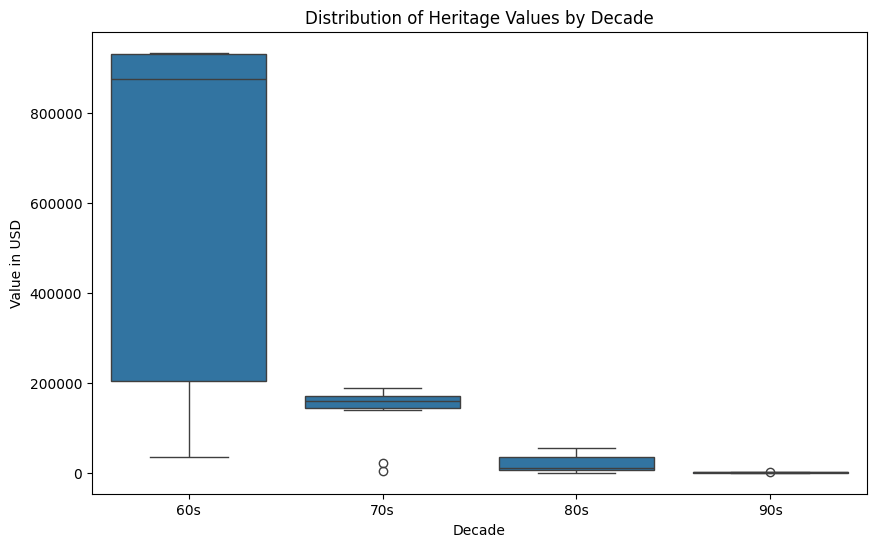

In [91]:
#Visualization 1
# Using box plots to show how values vary across members within each decade

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=heritage, x='decade', y='values ($)', ax=ax)


ax.set_title('Distribution of Heritage Values by Decade')
ax.set_xlabel('Decade')
ax.set_ylabel('Value in USD')


#Blox Plot Visualization
This box plot shows how the source Heritage varies in there colelction values across members within each decade. I formed this using the `sns.boxplot `function. The box covers the middle 50% of members, the line inside it is the median and the dots are outliers. The median value falls steeps with each decrease, from about `$874,00` in the 60s to about` $160,000` in the 70s and `$920` in the 90s The 60s plot is the largest because values range widely from about `$35,000` to over `$930,000`, although most members who own 1960s comics hold collections close to `$900,000`. This could also be from the missing values being concentrated in this decade. In the 70s the values are tightly grouped near the median with two lower outliers. Because this chart uses a regular dollar scale and the 1960s values are so large, the 1980s and 1990s boxes appear very small and flat, so the differences between those decades are hard to see here.


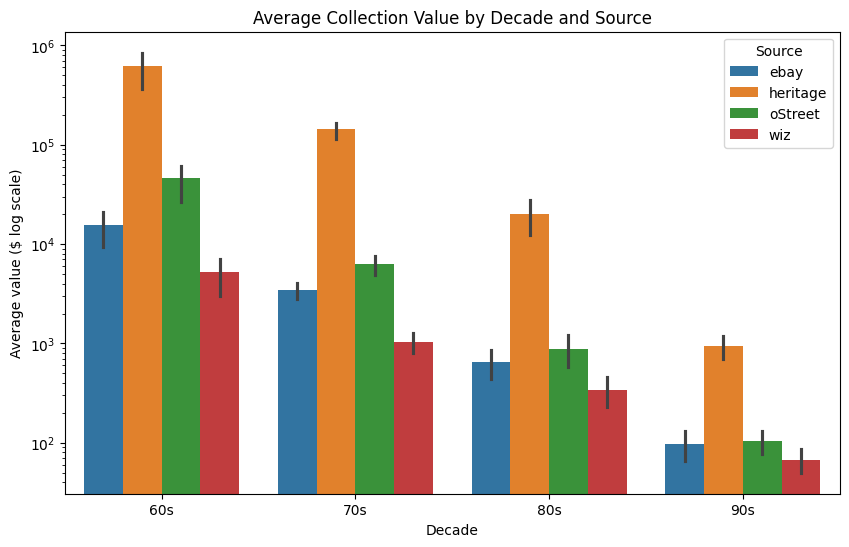

In [92]:
#Visualization 2
#comparing average log collection value by decade and by source

fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=df_long,
    x='decade',
    y='values ($)',
    hue='source',          # one bar color per source
    estimator='mean',
    ax=ax
)

ax.set_yscale('log')
ax.set_title('Average Collection Value by Decade and Source')
ax.set_xlabel('Decade')
ax.set_ylabel('Average value ($ log scale)')
ax.legend(title='Source')


#Visualization 2: Average collection value sorted by decade and source
This grouped bar graph compares the average collection value for each decade, with a bar per each source. I formed this using the `sns.barplot` function. The y-axis uses a log scale because the averages have a drastic range from under `$100` to over `$600,000` and on a regular scale the smaller bars would be basically invisible on the graph. Because of the log scale, each step ut the axis is a tenfold increase, so bars that look close in height can differ a lot in dollars. The chart shows the two patterns, first, values fall steeply from the 60s to the 90s in ever source. The average heritage value drops from about `$620,831` to `$944` and the other sources also fall a lot. Also, the se source consistnetly rank in the same order as I mentioned previously in this project.
